# MLP

**Run this notebook:** in Colab, choose **Runtime → Run all**. The first cell prepares METIS automatically using uv; a fresh runtime needs this setup again. These short tutorials use a CPU. Locally, select your [METIS Python environment](https://ojwatson.github.io/metis/basics/installing_metis.html).

The outputs below were generated when the documentation was built. [Source revision `ebd964ed89e4`](https://github.com/OJWatson/metis/tree/ebd964ed89e468e4f03197f2c0217c581e294b97).

In [ ]:
#@title Prepare METIS (run once per runtime)
"""Embedded in notebook downloads: prepare their disposable Colab runtime with uv."""

import importlib
import importlib.metadata
import importlib.util
import io
import json
import os
from pathlib import Path
import platform
import re
import shutil
import subprocess
import sys
import tarfile
import urllib.request


UV_VERSION = "0.7.22"
INSTALL_GUIDE = "https://ojwatson.github.io/metis/basics/installing_metis.html"


def _installed_version(package):
    try:
        return importlib.metadata.version(package)
    except importlib.metadata.PackageNotFoundError:
        return None


def _compatible_pin(package, minimum, maximum=None):
    """Preserve compatible binary libraries already supplied by Colab."""
    version = _installed_version(package)
    if version is None:
        return None
    match = re.match(r"^(\d+)\.(\d+)(?:\.(\d+))?", version)
    if match is None:
        return None
    release = tuple(int(value or 0) for value in match.groups())
    if release < minimum or (maximum is not None and release >= maximum):
        return None
    return f"{package}=={version}"


def _uv_executable(directory):
    installed = shutil.which("uv")
    if installed:
        return installed
    destination = directory / "uv"
    if not destination.exists():
        architecture = {"x86_64": "x86_64", "aarch64": "aarch64"}.get(platform.machine())
        if architecture is None:
            raise RuntimeError(f"Unsupported Colab CPU architecture: {platform.machine()}")
        archive_name = f"uv-{architecture}-unknown-linux-gnu"
        url = (
            f"https://github.com/astral-sh/uv/releases/download/{UV_VERSION}/"
            f"{archive_name}.tar.gz"
        )
        with urllib.request.urlopen(url, timeout=120) as response:
            archive_bytes = response.read()
        with tarfile.open(fileobj=io.BytesIO(archive_bytes), mode="r:gz") as archive:
            # Read one known member, without extracting arbitrary archive paths.
            binary = archive.extractfile(f"{archive_name}/uv")
            if binary is None:
                raise RuntimeError("The uv release archive contains no executable")
            destination.write_bytes(binary.read())
        destination.chmod(0o755)
    return str(destination)


def _project_text(revision):
    dependencies = [
        f"metis-surrogate[plots,pandas] @ git+https://github.com/OJWatson/metis.git@{revision}",
        "torch==2.10.0",
    ]
    for package, minimum, maximum in [
        ("numpy", (2, 0, 0), (3, 0, 0)),
        ("matplotlib", (3, 9, 0), (4, 0, 0)),
        ("pandas", (2, 2, 0), (4, 0, 0)),
        ("pyarrow", (18, 0, 0), None),
        ("polars", (1, 37, 0), (3, 0, 0)),
    ]:
        pin = _compatible_pin(package, minimum, maximum)
        if pin:
            dependencies.append(pin)
    return (
        '[project]\nname = "metis-colab-tutorial"\nversion = "0.0.0"\n'
        f'requires-python = ">={sys.version_info.major}.{sys.version_info.minor},'
        f'<{sys.version_info.major}.{sys.version_info.minor + 1}"\n'
        f"dependencies = {json.dumps(dependencies)}\n\n"
        '[tool.uv]\npackage = false\n\n'
        '[tool.uv.sources]\ntorch = { index = "pytorch-cpu" }\n\n'
        '[[tool.uv.index]]\nname = "pytorch-cpu"\n'
        'url = "https://download.pytorch.org/whl/cpu"\nexplicit = true\n'
    )


def _metis_origin():
    try:
        return importlib.metadata.distribution("metis-surrogate").read_text("direct_url.json")
    except importlib.metadata.PackageNotFoundError:
        return None


def prepare_colab(revision):
    """Install only inside Colab; local notebooks use the selected METIS environment."""
    if not re.fullmatch(r"[a-f0-9]{40}", revision):
        raise ValueError("Notebook setup needs an exact 40-character source revision")
    try:
        in_colab = (
            importlib.util.find_spec("google.colab") is not None
            and bool(os.environ.get("COLAB_RELEASE_TAG") or os.environ.get("COLAB_BACKEND_VERSION"))
        )
    except ModuleNotFoundError:
        in_colab = False
    if not in_colab:
        if _installed_version("metis-surrogate") is None:
            raise RuntimeError(f"Select a Python environment containing METIS: {INSTALL_GUIDE}")
        print(f"Using local METIS {_installed_version('metis-surrogate')}.")
        return
    if sys.version_info < (3, 11):
        raise RuntimeError("This tutorial requires a Colab runtime with Python 3.11 or newer.")

    directory = Path("/content/.metis-notebooks")
    directory.mkdir(parents=True, exist_ok=True)
    (directory / "pyproject.toml").write_text(_project_text(revision), encoding="utf-8")
    loaded = {
        package: str(getattr(sys.modules[package], "__version__", _installed_version(package)))
        for package in ("numpy", "pandas", "torch", "matplotlib", "pyarrow", "polars")
        if package in sys.modules
    }
    metis_was_loaded = "metis" in sys.modules
    previous_metis_origin = _metis_origin()
    if metis_was_loaded:
        # Retain the import's identity if the user reruns setup after a restart
        # warning without actually restarting the Python process.
        previous_metis_origin = sys.modules["metis"].__dict__.setdefault(
            "_notebook_runtime_origin", previous_metis_origin,
        )
    environment = os.environ.copy()
    # Colab is a disposable runtime. Keep its unrelated packages and its active
    # notebook interpreter, instead of adding a second environment to sys.path.
    environment["UV_PROJECT_ENVIRONMENT"] = sys.prefix
    environment.pop("VIRTUAL_ENV", None)
    print("Preparing this Colab runtime with uv (CPU tutorial environment)…")
    result = subprocess.run(
        [_uv_executable(directory), "sync", "--inexact", "--no-dev", "--no-editable",
         "--project", str(directory), "--python", sys.executable],
        env=environment, text=True, capture_output=True,
    )
    if result.returncode:
        raise RuntimeError(f"METIS setup failed:\n{result.stdout}\n{result.stderr}")
    importlib.invalidate_caches()
    changed = [package for package, before in loaded.items() if _installed_version(package) != before]
    if metis_was_loaded and _metis_origin() != previous_metis_origin:
        changed.append("metis")
    if changed:
        raise RuntimeError(
            "Setup updated already-loaded libraries (" + ", ".join(changed) + "). "
            "Choose Runtime > Restart session, then Run all. Setup will reuse its installed packages."
        )
    print(f"METIS {_installed_version('metis-surrogate')} is ready. Continue with the tutorial.")


prepare_colab("ebd964ed89e468e4f03197f2c0217c581e294b97")


The multilayer perceptron (MLP) is the simplest METIS surrogate. It maps static
inputs directly to a complete output trajectory. It is a useful first model:
fast to train, fast to predict, and easy to compare with more complex choices.

Its predictions are deterministic. It learns a mean-like response under squared
error, rather than generating the simulator's stochastic variation.

## Try it

This small continuous-valued example uses 40 parameter settings, four
realisations per setting and eight time points. The response is
$y(t)=\theta(1+\sin t)+0.3\cos t+\epsilon$, with independent
$\epsilon\sim N(0,0.08^2)$. The known mean lets us see what the surrogate learns.
This is a short teaching fit, not a benchmark of the model families.

In [1]:
#| code-fold: true
#| code-summary: "Create the example bank"
import numpy as np
import matplotlib.pyplot as plt
from metis import SimulationDataset, Surrogate, TrainingConfig

rng = np.random.default_rng(7)
times = np.linspace(0, 2, 8)
inputs = np.repeat(np.linspace(0.2, 1.2, 40)[:, None], 4, axis=0)
mean = inputs[:, None, :] * (1 + np.sin(times)[None, :, None])
mean = mean + 0.3 * np.cos(times)[None, :, None]
outputs = mean + rng.normal(0, 0.08, mean.shape)
bank = SimulationDataset.from_arrays(
    inputs, outputs, input_names=["theta"], output_names=["response"], times=times,
)
split = bank.split(seed=42)

In [2]:
model = Surrogate(
    "mlp",
    model_options={"hidden_dim": 32, "num_blocks": 1, "num_layers_per_block": 2},
).fit(
    split.train, split.validation,
    config=TrainingConfig(steps=300, batch_size=32, eval_every=50, seed=42),
)

Compare the prediction with the known mean and one held-out realisation.

In [3]:
theta = split.test.inputs[:1]
prediction = model.predict(theta)[0, :, 0]
expected = theta[0, 0] * (1 + np.sin(times)) + 0.3 * np.cos(times)
print(f"RMSE against the known mean at theta={theta[0, 0]:.3f}: "
      f"{np.sqrt(np.mean((prediction - expected) ** 2)):.3f}")

RMSE against the known mean at theta=0.456: 0.011


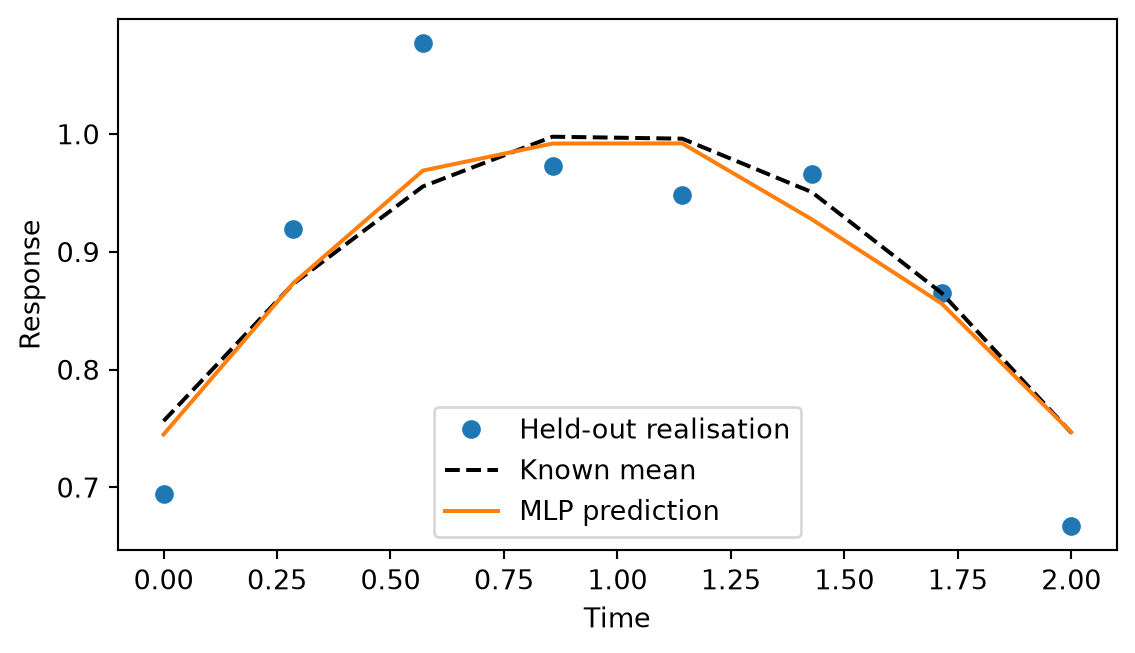

In [4]:
#| code-fold: true
#| code-summary: "Plot the held-out prediction"
#| fig-cap: "MLP: short CPU fit on the synthetic continuous bank. This parameter setting was withheld from training."
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(times, split.test.outputs[0, :, 0], "o", label="Held-out realisation")
ax.plot(times, expected, "--", color="black", label="Known mean")
ax.plot(times, prediction, label="MLP prediction")
ax.set(xlabel="Time", ylabel="Response")
ax.legend()
fig.tight_layout()
plt.show()

*MLP: short CPU fit on the synthetic continuous bank. This parameter setting was withheld from training.*

## How it works

A linear layer maps the inputs to a hidden vector. Residual blocks transform
that vector, then a final linear layer produces all time points and channels.
Each residual block adds its input back to the transformed vector:

![An MLP residual block adds its input to the output of its linear layers.](https://ojwatson.github.io/metis/models/images/residual-block.png)

Training minimizes mean squared error between standardized predictions and
simulations:

$$
\mathcal L(\theta)=\frac{1}{M}\sum_{m=1}^{M}
\left(\mathrm{MLP}_{\theta}(x_m)-y_m\right)^2.
$$

## Change its size

`hidden_dim` controls width, `num_blocks` the number of residual blocks, and
`num_layers_per_block` their depth. Input and output sizes come from the bank.
The default width is 64 with two blocks of two layers.

```bash
uv run metis train model=mlp model.model_options.hidden_dim=128
```

Increase capacity only if it improves validation predictions.